<div align="center">

# <span style="color:#1976D2;">Customer Churn Prediction and Retention Strategy Using Machine Learning — Milestone 2</span>

**Model Building, Performance Improvement, Comparison and Final Selection** 

**Continuation of:** *Customer Churn Prediction — Milestone 1* (the source notebook supplied as `Customer_Churn_Prediction.html`, Sections 1–3 before Model Development).

This notebook begins with a concise recap of Milestone 1, independently reloads the original data, recreates the exact cleaning, split and preprocessing definitions from Milestone 1, then proceeds directly to model building. No EDA or earlier narrative is repeated.

</div>

---

## Milestone 1 Recap and Milestone 2 Handoff


**Reference:** `Customer_Churn_Prediction.html` (Milestone 1 analysis). Milestone 1 examined 11,260 customers, 19 fields and approximately 16.8% churn; it included cleaning, feature exploration, an 80:20 stratified split and a Streamlit application.

**Milestone 2** reloads the source data and imports preprocessing from `scripts/preprocessing.py`, without repeating EDA, covering model building, hyperparameter tuning, performance comparison, final model selection, and automated churn prediction.

The best-performing model will be integrated into the existing **Streamlit application** and deployed through **ChurnGuard**, enabling interactive predictions and automated batch scoring of new customer datasets through GitHub Actions, without retraining.

---
## Import the necessary libraries

In [1]:
# Install the required libraries

# !python -m pip install --upgrade pip
# !python -m pip install pandas numpy matplotlib seaborn scikit-learn xgboost openpyxl ipykernel jupyter

In [34]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import time
from datetime import datetime
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV, ParameterGrid
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score, average_precision_score)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import json, joblib
from IPython.display import display
from xgboost import XGBClassifier

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.model_selection import train_test_split
from dotenv import load_dotenv
from getpass import getpass

import warnings
from sklearn.exceptions import ConvergenceWarning

# Suppress non-critical model warnings
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)


RANDOM_STATE = 42
load_dotenv()  # Load environment variables from .env file

True

---
## Configure Project Directories

In [3]:
# Locate the project root using existing project folders.
PROJECT_ROOT = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "data" / "Customer Churn Data.xlsx").is_file()
    and (p / "outputs").is_dir()
)

# Set the project root as the working directory.
os.chdir(PROJECT_ROOT)
#print("WORKING DIRECTORY:", PROJECT_ROOT)
print("WORKING DIRECTORY:", f"***/{Path.cwd().name}")


WORKING DIRECTORY: ***/CustomerChurnPrediction


In [4]:
# Define project directories.
INPUT_DIR = PROJECT_ROOT / "data_to_predict" # *.yml files for prediction
WORKFLOW_DIR = PROJECT_ROOT / ".github/workflows" # *.yml files for GitHub Actions
SCRIPT_DIR = PROJECT_ROOT / "scripts" # *.py files for data prediction and model deployment
DATA_DIR = PROJECT_ROOT / "data" # *.csv, *.xlsx files for training and testing
OUTPUT_DIR = PROJECT_ROOT / "outputs" # *.ipynb, *.pdf , •.html files for results
MODELS_DIR = PROJECT_ROOT / "models" # *.joblib files for trained models
DEPLOYMENT_DIR = PROJECT_ROOT / ".streamlit" # •.toml files for Streamlit deployment

# Create directories if missing.
for path in [INPUT_DIR, WORKFLOW_DIR,SCRIPT_DIR, DATA_DIR, OUTPUT_DIR,MODELS_DIR, DEPLOYMENT_DIR]:
    path.mkdir(parents=True, exist_ok=True)

# Display directory paths.
print("\nPROJECT DIRECTORIES")
for path in [INPUT_DIR, WORKFLOW_DIR,SCRIPT_DIR, DATA_DIR, OUTPUT_DIR,MODELS_DIR, DEPLOYMENT_DIR]:
    print(f"***/{path.relative_to(PROJECT_ROOT.parent)}")


PROJECT DIRECTORIES
***/CustomerChurnPrediction/data_to_predict
***/CustomerChurnPrediction/.github/workflows
***/CustomerChurnPrediction/scripts
***/CustomerChurnPrediction/data
***/CustomerChurnPrediction/outputs
***/CustomerChurnPrediction/models
***/CustomerChurnPrediction/.streamlit


---
## 1. Milestone 1 Summary

In [5]:
# Load data

FILE_PATH = DATA_DIR / "Customer Churn Data.xlsx"

if FILE_PATH.exists():
    print(f"Dataset found: ***/{FILE_PATH.relative_to(PROJECT_ROOT)}")
else:
    raise FileNotFoundError("Dataset not found in data/ directory.")

Dataset found: ***/data/Customer Churn Data.xlsx


### Reproduce Milestone 1's data handoff, without rerunning EDA.

In [6]:
# Load dataset into a pandas DataFrame
df = pd.read_excel(FILE_PATH, sheet_name="Data for DSBA")

# Standardize column names & values by stripping whitespace and converting to lowercase.
df.columns = df.columns.str.strip().str.lower()

df.head()

,accountid,churn,tenure,city_tier,cc_contacted_ly,payment,gender,service_score,account_user_count,account_segment,cc_agent_score,marital_status,rev_per_month,complain_ly,rev_growth_yoy,coupon_used_for_payment,day_since_cc_connect,cashback,login_device
0,20000,1,4,3.0,6.0,Debit Card,Female,3.0,3,Super,2.0,Single,9,1.0,11,1,5,159.93,Mobile
1,20001,1,0,1.0,8.0,UPI,Male,3.0,4,Regular Plus,3.0,Single,7,1.0,15,0,0,120.9,Mobile
2,20002,1,0,1.0,30.0,Debit Card,Male,2.0,4,Regular Plus,3.0,Single,6,1.0,14,0,3,NaN,Mobile
3,20003,1,0,3.0,15.0,Debit Card,Male,2.0,4,Super,5.0,Single,8,0.0,23,0,3,134.07,Mobile
4,20004,1,0,1.0,12.0,Credit Card,Male,2.0,3,Regular Plus,5.0,Single,3,0.0,11,1,3,129.6,Mobile


In [7]:
from scripts.preprocessing import build_preprocessor # import the build_preprocessor function from preprocessing.py

# Set the target column and identifier column for the dataset.
TARGET_COL = "churn"
id_cols = "accountid"

# Split before fitting imputation, encoding or scaling.
X = df.drop(columns=[TARGET_COL, id_cols])
y = df[TARGET_COL]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Retain account IDs for campaign targeting.
train_accounts = df.loc[X_train.index, id_cols].copy()
test_accounts = df.loc[X_test.index, id_cols].copy()

# Apply preprocessing to the training data and retain the fitted preprocessor for later use on new data.
preprocessor = build_preprocessor(X_train)
assert set(X_train.index).isdisjoint(X_test.index)

print(f"Dataset: ***/data/{FILE_PATH.name} | Train: {len(X_train):,} | Test: {len(X_test):,}")
print(f"Features: {X_train.shape[1]} | Churn: {y_train.mean():.2%} train, {y_test.mean():.2%} test")
print("Shared preprocessing module ready (unfitted).")



Dataset: ***/data/Customer Churn Data.xlsx | Train: 9,008 | Test: 2,252
Features: 17 | Churn: 16.84% train, 16.83% test
Shared preprocessing module ready (unfitted).


**Milestone 1 continuity and deployment note:** This notebook reconstructs the data handoff and preprocessing from Milestone 1, then starts model building. The automated churn-prediction application was already developed; this milestone benchmarks and tunes additional algorithms. Replacing the deployed model requires exporting the final fitted preprocessing-and-classifier pipeline and validating that the application uses the same feature schema. No deployment or prediction results are claimed until tested.

---
## 2. Model Building and Evaluation 

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 2.1 Models and metric choice



Building on Milestone 1, nine classification models are evaluated to predict customer churn.

| Model | Purpose | Source |
|---|---|---|
| Logistic Regression | Linear baseline | Milestone 1 |
| Decision Tree | Nonlinear patterns | Milestone 1 |
| Random Forest | Ensemble stability | Milestone 1 |
| Gradient Boosting | Sequential learning | Milestone 1 |
| XGBoost | Optimized boosting | Milestone 1 |
| KNN | Distance-based classification | New |
| Gaussian Naive Bayes | Probabilistic classification | New |
| SVM (RBF) | Nonlinear decision boundaries | New |
| Extra Trees | Randomized ensemble | New |

**F1** is the primary selection metric due to churn imbalance (~16.8%), supported by precision, recall, PR-AUC, ROC-AUC and confusion matrices. Preprocessing is fitted within each training fold.

All models use consistent preprocessing and stratified cross-validation to ensure fair comparison. The best-performing model will be considered for integration with the existing ChurnGuard automated prediction pipeline.

#### Helper Function

In [8]:
%%writefile scripts/preprocessing.py
"""Shared, serializable preprocessing for training and ChurnGuard inference."""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERIC_FIX_COLS = ("tenure", "account_user_count", "rev_per_month", "rev_growth_yoy", "coupon_used_for_payment", "day_since_cc_connect", "cashback")
DISCRETE_CANDIDATES = ("account_user_count", "complain_ly")
CATEGORY_MAPS = {
    "gender": {"m": "male", "f": "female"},
    "login_device": {"&&&&": "others"},
    "account_segment": {"regular +": "regular plus", "super +": "super plus"},
}

class NormalizeChurnFeatures(BaseEstimator, TransformerMixin):
    """Normalize numeric and categorical features while preserving column names."""

    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Expected a pandas DataFrame")
        self.feature_names_in_ = list(X.columns)
        return self

    def transform(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Expected a pandas DataFrame")

        missing = set(self.feature_names_in_) - set(X.columns)
        if missing:
            raise ValueError(f"Missing required features: {sorted(missing)}")

        out = X.loc[:, self.feature_names_in_].copy()

        # Convert numeric text
        for col in NUMERIC_FIX_COLS:
            if col in out:
                out[col] = pd.to_numeric(out[col], errors="coerce")

        # Normalize categorical values
        for col in out.columns:
            if col not in NUMERIC_FIX_COLS and (
                pd.api.types.is_object_dtype(out[col])
                or pd.api.types.is_string_dtype(out[col])
            ):
                out[col] = (
                    out[col].astype("string")
                    .str.strip()
                    .str.lower()
                    .astype(object)
                )

        # Standardize categorical labels
        for col, mapping in CATEGORY_MAPS.items():
            if col in out:
                out[col] = out[col].replace(mapping)

        # Ensure compatibility with sklearn SimpleImputer
        out = out.astype(object).replace({pd.NA: np.nan})

        return out


def build_preprocessor(X):
    """Create unfitted preprocessing; call on the raw feature DataFrame."""
    num_cols = list(dict.fromkeys(list(X.select_dtypes(include="number").columns) + [c for c in NUMERIC_FIX_COLS if c in X.columns]))
    cat_cols = [c for c in X.columns if c not in num_cols]
    discrete_cols = [c for c in DISCRETE_CANDIDATES if c in num_cols]
    continuous_cols = [c for c in num_cols if c not in discrete_cols]
    columns = ColumnTransformer([
        ("continuous", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), continuous_cols),
        ("discrete", SimpleImputer(strategy="most_frequent"), discrete_cols),
        ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ])
    return Pipeline([("normalize", NormalizeChurnFeatures()), ("columns", columns)])


Overwriting scripts/preprocessing.py


In [9]:
# Train models using identical preprocessing.
def train_models(models, preprocessor, X_train, y_train):
    """Fit each model with a fresh copy of the shared preprocessing pipeline.
       Displays training progress, and returns a dictionary of trained models for evaluation and comparison.
    """
    trained = {}
    for name, model in models.items():
        # Keep preprocessing and classifier instances independent for each model.
        pipeline = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("classifier", clone(model)),
        ])
        trained[name] = pipeline.fit(X_train, y_train)
        print(f"{name}: Training completed")
    return trained

In [10]:
# Evaluate the selected model on the held-out test set ONLY after model selection.
def evaluate_final_model(name, model, X_test, y_test):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    result = pd.DataFrame([{
        "Model": name, "Dataset": "Test",
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob),
    }])
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1], display_labels=["Retained", "Churned"],
        cmap="Blues", colorbar=False
    )
    plt.title(f"Final held-out test: {name}")
    plt.show()
    return result

In [11]:
# Tune each model with stratified cross-validation and rank by validation F1.

def tune_models(models, tuning_params, preprocessor, X_train, y_train):
    """Return the best fitted model and CV summary for each classifier."""
    # Preserve churn proportions in each fold.
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    tuned_models, results = {}, []
    total_models = len(models)
    overall_start = time.perf_counter()

    def log(message):
        timestamp = datetime.now().strftime("%H:%M:%S")
        print(f"[{timestamp}] {message}", flush=True)

    log(f"Starting hyperparameter tuning: {total_models} models")
    log(f"Training records: {len(X_train):,} | Features: {X_train.shape[1]}")
    log("Selection metric: F1 | Cross-validation: 5 folds")
    print(flush=True)

    for index, (name, model) in enumerate(models.items(), start=1):
        start_time = time.perf_counter()
        n_candidates = min(20, len(ParameterGrid(tuning_params[name])))

        log(f"[{index}/{total_models}] Tuning {name}")
        log(f"  Search candidates: {n_candidates} | CV fits: {n_candidates * 5}")

        # Clone preprocessing and classifier so each search is independent.
        pipeline = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("classifier", clone(model)),
        ])

        # Search parameter combinations using F1 score.
        search = RandomizedSearchCV(
            pipeline,
            tuning_params[name],
            n_iter=n_candidates,
            scoring="f1",
            cv=cv,
            n_jobs=1,
            random_state=42,
            verbose=1,
            refit=True,
            error_score="raise",
        )

        log(f"  {name}: Running hyperparameter search...")
        search.fit(X_train, y_train)

        tuned_models[name] = search.best_estimator_
        results.append({
            "Model": name,
            "CV F1": search.best_score_,
            "Best Parameters": search.best_params_,
        })

        elapsed = time.perf_counter() - start_time

        log(f"  {name}: Completed | Best CV F1={search.best_score_:.4f}")
        log(f"  Best parameters: {search.best_params_}")
        log(f"  Execution time: {elapsed:.1f}s")

        # Add a blank line between model tuning results.
        print(flush=True)

    # Summarize models from highest to lowest cross-validation F1.
    summary = (
        pd.DataFrame(results)
        .sort_values("CV F1", ascending=False)
        .set_index("Model")
    )

    log(f"All tuning completed in {(time.perf_counter() - overall_start) / 60:.1f} minutes")
    log(f"Best tuned model: {summary.index[0]} | CV F1={summary.iloc[0]['CV F1']:.4f}")

    display(summary.round(3))
    return tuned_models, summary



In [12]:
# Compare models with stratified CV and plot out-of-fold confusion matrices.
def evaluate_cv(models, preprocessor, X_train, y_train):
    """Rank models by 5-fold F1 score and show their out-of-fold confusion matrices."""
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scoring = {
        "Precision": "precision", "Recall": "recall", "F1": "f1",
        "ROC-AUC": "roc_auc", "PR-AUC": "average_precision",
    }
    results, matrices = [], {}
    total_models = len(models)

    def log(message):
        timestamp = datetime.now().strftime("%H:%M:%S")
        print(f"[{timestamp}] {message}", flush=True)

    log(f"Starting baseline evaluation: {total_models} models, 5-fold stratified CV")
    log(f"Training records: {len(X_train):,} | Features: {X_train.shape[1]}")
    log("Evaluation metrics: Precision, Recall, F1, ROC-AUC, PR-AUC")

    for index, (name, model) in enumerate(models.items(), start=1):
        start_time = time.perf_counter()
        log(f"[{index}/{total_models}] Evaluating {name}")

        # Use existing pipelines as-is; otherwise add shared preprocessing.
        pipeline = clone(model) if isinstance(model, Pipeline) else Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("classifier", clone(model)),
        ])

        log(f"  {name}: Running 5-fold cross-validation...")
        scores = cross_validate(
            pipeline, X_train, y_train,
            cv=cv, scoring=scoring, n_jobs=1, error_score="raise"
        )

        # Out-of-fold predictions keep each row unseen during its prediction.
        log(f"  {name}: Generating out-of-fold predictions...")
        pred = cross_val_predict(
            pipeline, X_train, y_train, cv=cv, n_jobs=1
        )

        results.append({
            "Model": name,
            **{metric: scores[f"test_{metric}"].mean() for metric in scoring},
            "PR-AUC SD": scores["test_PR-AUC"].std(),
        })
        matrices[name] = confusion_matrix(y_train, pred, labels=[0, 1])

        elapsed = time.perf_counter() - start_time
        log(
            f"  {name}: Completed | "
            f"F1={results[-1]['F1']:.4f} | "
            f"PR-AUC={results[-1]['PR-AUC']:.4f} | "
            f"Time={elapsed:.1f}s"
        )

    # Add a blank line between model evaluations.
        print(flush=True)

    # Sort models by mean cross-validation F1 score.
    cv_df = (
        pd.DataFrame(results)
        .sort_values("F1", ascending=False)
        .set_index("Model")
    )

    log("All baseline evaluations completed. Displaying results.")
    display(cv_df.T.round(4))

    # Plot out-of-fold confusion matrices in a compact grid.
    n_models = len(cv_df)
    n_cols = 3
    n_rows = (n_models + n_cols - 1) // n_cols

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(15, 4 * n_rows),
        squeeze=False
    )

    for ax, name in zip(axes.ravel(), cv_df.index):
        ConfusionMatrixDisplay(
            confusion_matrix=matrices[name],
            display_labels=["Retained", "Churned"]
        ).plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(name)

    # Hide unused subplot axes.
    for ax in axes.ravel()[n_models:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    log(f"Best baseline model by F1: {cv_df.index[0]}")
    return cv_df


<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 2.2 Configure nine baseline models

In [13]:
# Six complementary model families; churn weighting is computed from training labels only.
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=1),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "SVM (RBF)": SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=1),
    "XGBoost": XGBClassifier(n_estimators=200, scale_pos_weight=scale_pos_weight, eval_metric="logloss", random_state=42, n_jobs=1),
}

In [14]:
# Train Baseline Models
trained_models = train_models(models, preprocessor, X_train, y_train)

# Summarize trained models.
model_summary = pd.DataFrame({
    "Model": list(trained_models),
    "Training Records": len(X_train),
    "Features": X_train.shape[1],
    "Status": "Trained"
})

display(model_summary)


Logistic Regression: Training completed
Decision Tree: Training completed
Gradient Boosting: Training completed
Extra Trees: Training completed
KNN: Training completed
Naive Bayes: Training completed
SVM (RBF): Training completed
Random Forest: Training completed
XGBoost: Training completed


,Model,Training Records,Features,Status
0,Logistic Regression,9008,17,Trained
1,Decision Tree,9008,17,Trained
2,Gradient Boosting,9008,17,Trained
3,Extra Trees,9008,17,Trained
4,KNN,9008,17,Trained
5,Naive Bayes,9008,17,Trained
6,SVM (RBF),9008,17,Trained
7,Random Forest,9008,17,Trained
8,XGBoost,9008,17,Trained


<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 2.3 Baseline training overview

All nine classification models were successfully trained using 9,008 customer records and 17 features, with consistent preprocessing. The models are now ready for baseline performance evaluation and hyperparameter tuning to identify the best-performing churn predictor.

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 2.4 Baseline performance — five-fold stratified cross-validation

[17:45:04] Starting baseline evaluation: 9 models, 5-fold stratified CV
[17:45:04] Training records: 9,008 | Features: 17
[17:45:04] Evaluation metrics: Precision, Recall, F1, ROC-AUC, PR-AUC
[17:45:04] [1/9] Evaluating Logistic Regression
[17:45:04]   Logistic Regression: Running 5-fold cross-validation...
[17:45:04]   Logistic Regression: Generating out-of-fold predictions...
[17:45:05]   Logistic Regression: Completed | F1=0.5365 | PR-AUC=0.6155 | Time=0.7s

[17:45:05] [2/9] Evaluating Decision Tree
[17:45:05]   Decision Tree: Running 5-fold cross-validation...
[17:45:05]   Decision Tree: Generating out-of-fold predictions...
[17:45:05]   Decision Tree: Completed | F1=0.8194 | PR-AUC=0.7014 | Time=0.9s

[17:45:05] [3/9] Evaluating Gradient Boosting
[17:45:05]   Gradient Boosting: Running 5-fold cross-validation...
[17:45:10]   Gradient Boosting: Generating out-of-fold predictions...
[17:45:14]   Gradient Boosting: Completed | F1=0.6862 | PR-AUC=0.8027 | Time=8.7s

[17:45:14] [4/9] E

Model,Extra Trees,XGBoost,Random Forest,Decision Tree,KNN,Gradient Boosting,SVM (RBF),Logistic Regression,Naive Bayes
Precision,0.9846,0.9125,0.9688,0.8163,0.8848,0.8139,0.5305,0.4094,0.4152
Recall,0.8840,0.9051,0.8141,0.8227,0.7502,0.5939,0.8510,0.7785,0.6322
F1,0.9316,0.9086,0.8847,0.8194,0.8118,0.6862,0.6535,0.5365,0.5007
ROC-AUC,0.9971,0.9903,0.9933,0.8926,0.9698,0.9345,0.9245,0.8493,0.7780
PR-AUC,0.9885,0.9688,0.9743,0.7014,0.8739,0.8027,0.7557,0.6155,0.4491
PR-AUC SD,0.0045,0.0109,0.0074,0.0111,0.0145,0.0262,0.0215,0.0207,0.0397


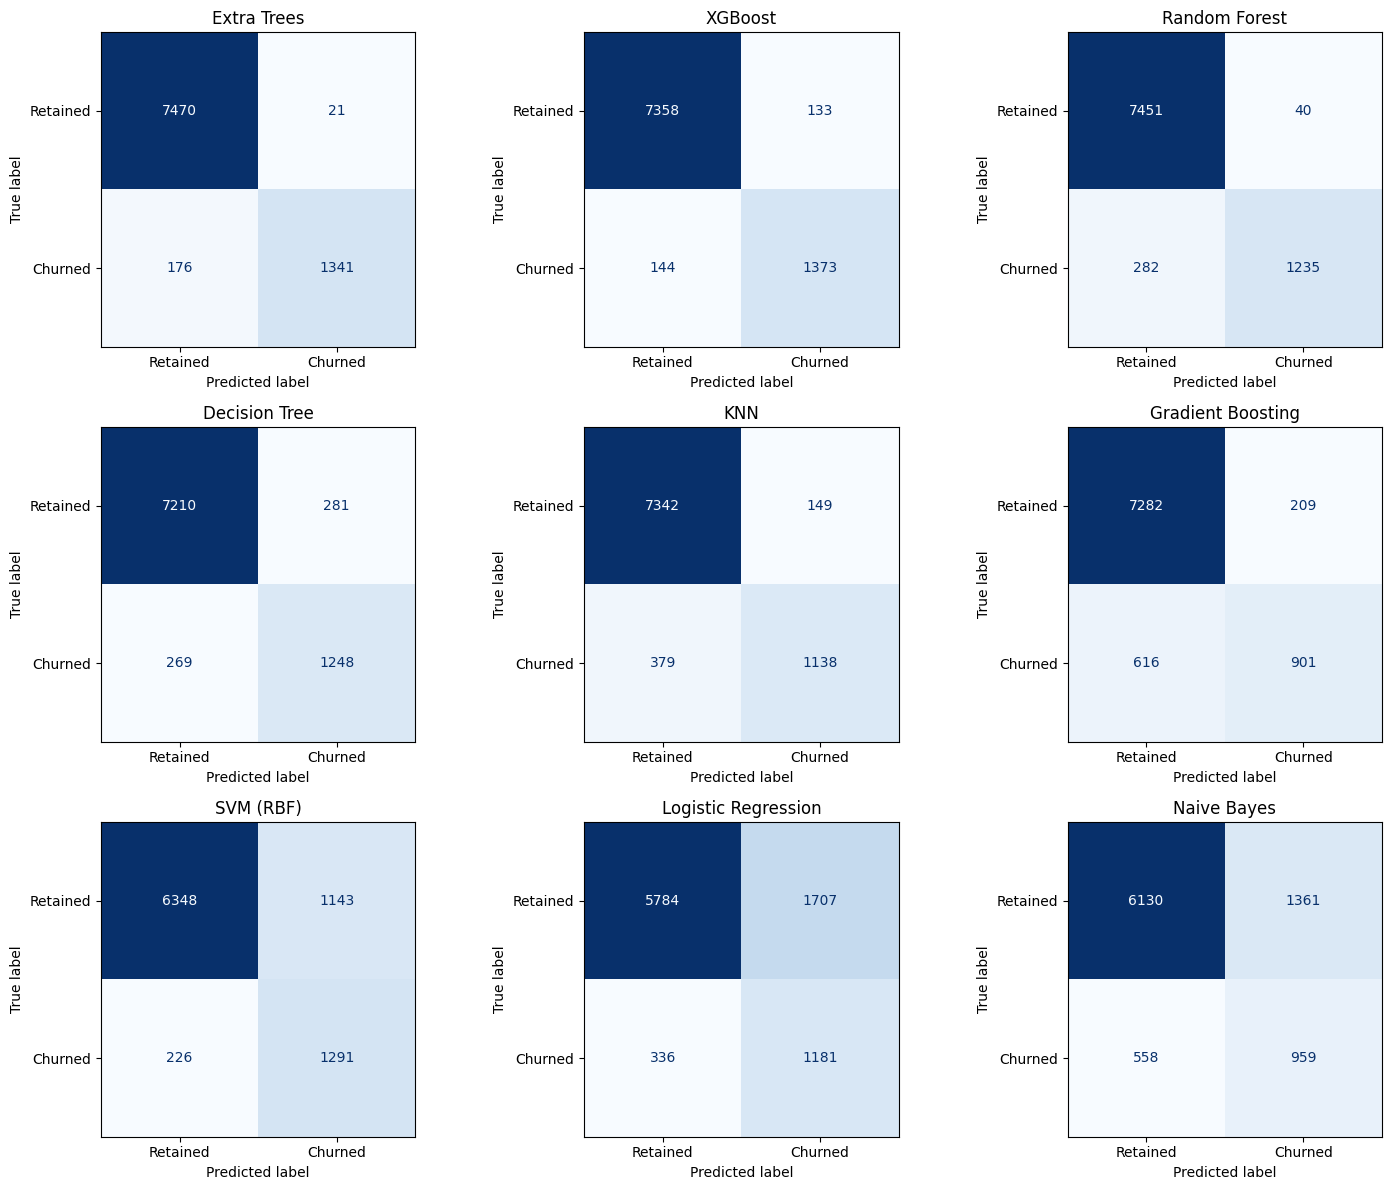

[17:46:12] Best baseline model by F1: Extra Trees


,Precision,Recall,F1,ROC-AUC,PR-AUC,PR-AUC SD
Model,,,,,,
Extra Trees,0.9846,0.8840,0.9316,0.9971,0.9885,0.0045
XGBoost,0.9125,0.9051,0.9086,0.9903,0.9688,0.0109
Random Forest,0.9688,0.8141,0.8847,0.9933,0.9743,0.0074
Decision Tree,0.8163,0.8227,0.8194,0.8926,0.7014,0.0111
KNN,0.8848,0.7502,0.8118,0.9698,0.8739,0.0145
Gradient Boosting,0.8139,0.5939,0.6862,0.9345,0.8027,0.0262
SVM (RBF),0.5305,0.8510,0.6535,0.9245,0.7557,0.0215
Logistic Regression,0.4094,0.7785,0.5365,0.8493,0.6155,0.0207
Naive Bayes,0.4152,0.6322,0.5007,0.7780,0.4491,0.0397


In [15]:
# Evaluate baseline models using only the training set (no test-set inspection).
baseline_cv_results = evaluate_cv(
    trained_models, preprocessor, X_train, y_train
)

display(baseline_cv_results.round(4))

**Baseline Model Evaluation — Observations**

- Extra Trees achieved the strongest overall performance, balancing precision and recall with minimal classification errors, and correctly identifying 1,341 churners, with only 21 retained customers incorrectly classified as churners and 176 churners missed. 

- XGBoost and Random Forest also performed well. XGBoost identified more churners (1,373) but incorrectly classified 133 retained customers while Random Forest missed 282 churners.

- The remaining models showed higher classification errors. Extra Trees, XGBoost, and Random Forest are the leading candidates for hyperparameter tuning.

---
## 3. Model Improvement, Comparison and Final Selection (15 points)

All nine models undergo hyperparameter tuning using 5-fold stratified cross-validation, with F1 as the primary selection metric. The highest cross-validation score may be optimistic due to model selection. The untouched test set will therefore be used only to evaluate the final selected model.

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 3.1 Hyperparameter Tuning

In [16]:
# Define hyperparameter search spaces for all nine classifiers.
tuning_params = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10],
        "classifier__class_weight": [None, "balanced"]
    },
    "Decision Tree": {
        "classifier__max_depth": [None, 5, 10, 20],
        "classifier__min_samples_leaf": [1, 3, 5]
    },
    "Gradient Boosting": {
        "classifier__n_estimators": [100, 200],
        "classifier__learning_rate": [0.03, 0.1],
        "classifier__max_depth": [2, 3]
    },
    "Extra Trees": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_leaf": [1, 3]
    },
    "KNN": {
        "classifier__n_neighbors": [3, 5, 9, 15, 25],
        "classifier__weights": ["uniform", "distance"],
        "classifier__p": [1, 2]
    },
    "Naive Bayes": {
        "classifier__var_smoothing": [1e-11, 1e-10, 1e-9, 1e-8, 1e-7]
    },
    "SVM (RBF)": {
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", 0.01, 0.1]
    },
    "Random Forest": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [None, 8, 15],
        "classifier__min_samples_leaf": [1, 3, 5]
    },
    "XGBoost": {
        "classifier__n_estimators": [100, 200, 350],
        "classifier__max_depth": [3, 5, 7],
        "classifier__learning_rate": [0.03, 0.1],
        "classifier__subsample": [0.8, 1.0],
        "classifier__colsample_bytree": [0.8, 1.0]
    }
}

In [17]:
# Train tuned Models
tuned_models, tuning_results = tune_models(
    models, tuning_params, preprocessor, X_train, y_train
)

[17:46:12] Starting hyperparameter tuning: 9 models
[17:46:12] Training records: 9,008 | Features: 17
[17:46:12] Selection metric: F1 | Cross-validation: 5 folds

[17:46:12] [1/9] Tuning Logistic Regression
[17:46:12]   Search candidates: 8 | CV fits: 40
[17:46:12]   Logistic Regression: Running hyperparameter search...
Fitting 5 folds for each of 8 candidates, totalling 40 fits
[17:46:14]   Logistic Regression: Completed | Best CV F1=0.5370
[17:46:14]   Best parameters: {'classifier__class_weight': 'balanced', 'classifier__C': 0.1}
[17:46:14]   Execution time: 2.7s

[17:46:14] [2/9] Tuning Decision Tree
[17:46:14]   Search candidates: 12 | CV fits: 60
[17:46:14]   Decision Tree: Running hyperparameter search...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
[17:46:19]   Decision Tree: Completed | Best CV F1=0.8194
[17:46:19]   Best parameters: {'classifier__min_samples_leaf': 1, 'classifier__max_depth': None}
[17:46:19]   Execution time: 4.4s

[17:46:19] [3/9] Tuning Gra

,CV F1,Best Parameters
Model,,
Extra Trees,0.937,"{'classifier__n_estimators': 200, 'classifier_..."
KNN,0.923,"{'classifier__weights': 'distance', 'classifie..."
XGBoost,0.911,"{'classifier__subsample': 0.8, 'classifier__n_..."
SVM (RBF),0.903,"{'classifier__gamma': 0.1, 'classifier__C': 10}"
Random Forest,0.885,"{'classifier__n_estimators': 100, 'classifier_..."
Decision Tree,0.819,"{'classifier__min_samples_leaf': 1, 'classifie..."
Gradient Boosting,0.722,"{'classifier__n_estimators': 200, 'classifier_..."
Logistic Regression,0.537,"{'classifier__class_weight': 'balanced', 'clas..."
Naive Bayes,0.501,{'classifier__var_smoothing': 1e-11}


**Hyperparameter Tuning — Observations**

Extra Trees retained the highest F1 score after tuning, confirming its strong baseline performance. KNN and SVM showed notable improvements, moving ahead of several ensemble models, while XGBoost remained competitive.

Extra Trees is the leading candidate for final model selection, subject to comparison with baseline results and evaluation on the untouched test set.

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 3.2 Baseline vs tuned comparison (training data only)

In [18]:
# Compare baseline and tuned cross-validation F1 scores without using test data.
comparison = pd.DataFrame({
    "Baseline F1": baseline_cv_results["F1"],
    "Tuned F1": tuning_results["CV F1"],
})

# Calculate the improvement in F1 after hyperparameter tuning.
comparison["F1 Change"] = comparison["Tuned F1"] - comparison["Baseline F1"]

# Sort models by tuned cross-validation F1 score.
comparison = comparison.sort_values("Tuned F1", ascending=False)

display(comparison.round(4))

,Baseline F1,Tuned F1,F1 Change
Model,,,
Extra Trees,0.9316,0.9369,0.0054
KNN,0.8118,0.9232,0.1115
XGBoost,0.9086,0.9110,0.0025
SVM (RBF),0.6535,0.9026,0.2490
Random Forest,0.8847,0.8849,0.0002
Decision Tree,0.8194,0.8194,0.0000
Gradient Boosting,0.6862,0.7223,0.0361
Logistic Regression,0.5365,0.5370,0.0005
Naive Bayes,0.5007,0.5007,0.0000


**Model Comparison — Observations**

Extra Trees maintained the highest F1 score after tuning, making its tuned version the leading candidate for final model selection. SVM and KNN achieved the largest improvements, while XGBoost remained competitive. Random Forest and Decision Tree showed little or no improvement. Based on the selection criteria, the tuned Extra Trees model will be selected for final evaluation on the untouched test set and, subject to satisfactory performance, deployment.

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 3.3 Final model selection by tuning CV F1

Following hyperparameter tuning and performance comparison, the best-performing tuned model will be selected based on its cross-validation F1 score. This model will proceed to final evaluation on the untouched test set to assess its ability to predict customer churn on unseen data.

In [19]:
# Rank tuned models by cross-validation F1 score.
cv_comparison = tuning_results[["CV F1"]].sort_values(
    "CV F1", ascending=False
)

display(cv_comparison.round(4))

# Select the best-performing tuned model.
best_model_name = cv_comparison.index[0]
best_model = tuned_models[best_model_name]

print(f"\nSelected Model: {best_model_name}")
print(f"CV F1: {cv_comparison.iloc[0]['CV F1']:.4f}")

,CV F1
Model,
Extra Trees,0.9369
KNN,0.9232
XGBoost,0.9110
SVM (RBF),0.9026
Random Forest,0.8849
Decision Tree,0.8194
Gradient Boosting,0.7223
Logistic Regression,0.5370
Naive Bayes,0.5007



Selected Model: Extra Trees
CV F1: 0.9369


<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 3.4 Final held-out test evaluation (selected model only)

The selected tuned Extra Trees model will be evaluated on the previously unseen test set to assess its generalization performance. Precision, recall, F1, ROC-AUC, PR-AUC, and the confusion matrix will be used to measure its effectiveness in identifying customer churn and determine its suitability for deployment.



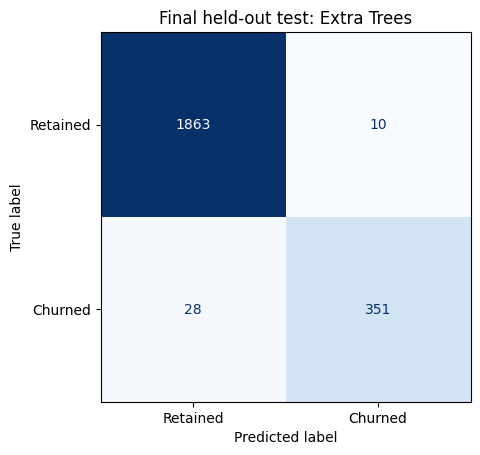

,,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Model,Dataset,,,,,,
Extra Trees,Test,0.9831,0.9723,0.9261,0.9486,0.9973,0.9892


In [20]:
# This cell evaluates the selected tuned model on the untouched test set, providing an independent assessment of its performance on unseen customer data.

final_results = evaluate_final_model(
    best_model_name, best_model, X_test, y_test
)

display(final_results.set_index(["Model", "Dataset"]).round(4))

**Final Test Evaluation — Observations**

The tuned Extra Trees model demonstrated strong performance on unseen data, confirming its ability to generalize beyond training. The confusion matrix shows 351 correctly identified churners, with only 28 churners missed and 10 retained customers incorrectly classified as churners.

The consistently high evaluation metrics support its selection as the final model for ChurnGuard deployment.

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 3.5 Conclusion and rationale


Nine classification models were evaluated using five-fold stratified cross-validation, with F1 as the primary selection metric. Hyperparameter tuning improved several models, particularly SVM and KNN, while Extra Trees maintained the strongest overall performance.

The tuned Extra Trees model was selected and evaluated once on the untouched test set. Its strong precision, recall, and F1 score, together with the confusion matrix results, demonstrate effective churn identification and performance consistent with cross-validation.

Although hyperparameter search scores may be optimistic, the independent test results support tuned Extra Trees as the final model for ChurnGuard deployment.

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 3.6 Model Export for Deployment

The selected tuned Extra Trees model is saved alongside its fitted preprocessing pipeline to ensure consistent predictions on new customer data. The exported model will be used by ChurnGuard's automated prediction workflow in Section 3, following deployment validation.

In [21]:
# Export the selected tuned model with its preprocessing pipeline.
model_filename = "churnguard_best_model.joblib"
model_path = MODELS_DIR / model_filename

MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(best_model, model_path)

# Display model details without exposing the full file path.
print(f"Selected Model: {best_model_name}")
print(f"Saved Model: ****/{MODELS_DIR.name}/{model_filename}")

Selected Model: Extra Trees
Saved Model: ****/models/churnguard_best_model.joblib


In [22]:
# Verify the exported model can be loaded and used for prediction.
loaded_model = joblib.load(model_path)

assert loaded_model.predict(X_test.head(5)).tolist() == \
       best_model.predict(X_test.head(5)).tolist()

print("Model export and reload verification successful.")

Model export and reload verification successful.


---
## 4. Automated Churn Prediction and Deployment

This section integrates the selected tuned Extra Trees model into ChurnGuard's existing prediction workflow. The system processes new or updated customer datasets, validates input features, generates churn probabilities, assigns risk segments, and recommends retention actions.

The implementation uses scripts/predict_changed.py and the exported model, ensuring consistency between notebook predictions and automated execution.


<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 4.1 Deployment Architecture

ChurnGuard uses an automated batch prediction workflow to identify customers at risk of churn. The workflow integrates the selected tuned Extra Trees model with the a prediction script, feature schema, and GitHub Actions automation.

The deployment reuses the existing infrastructure rather than introducing a separate prediction system.


```mk
                         CHURNGUARD AUTOMATED PREDICTION
                                      │
                                      ▼
┌──────────────────────────┐  ┌──────────────────────────────┐  ┌────────────────────────────────────┐
│ STAGE 1                  │  │ STAGE 2                      │  │ STAGE 3                            │
│ DATA INPUT & TRIGGER     │  │ VALIDATION & PREDICTION      │  │ OUTPUT & RETENTION ACTIONS         │
│                          │  │                              │  │                                    │
│ Customer Data            │  │ scripts/predict_changed.py   │  │ Churn Probability                  │
│ (CSV / XLSX)             │  │          │                   │  │         │                          │
│        │                 │  │          ▼                   │  │         ▼                          │
│        ▼                 │  │ Input Validation             │  │ Risk Segmentation                  │
│ data_to_predict/         │  │          │                   │  │ Low / Moderate / High / Critical   │
│        │                 │  │          ▼                   │  │         │                          │
│        ▼                 │  │ Feature Preprocessing        │  │         ▼                          │
│ GitHub Push / Manual Run │  │          │                   │  │ Revenue at Risk                    │
│        │                 │  │          ▼                   │  │         │                          │
│        ▼                 │  │ Tuned Extra Trees Model      │  │         ▼                          │
│ GitHub Actions           │  │ (Saved Pipeline)             │  │ Retention Recommendations          │
│        │                 │  │          │                   │  │         │                          │
│        └─────────────────┼─▶│          └───────────────────┼─▶│         ▼                          │
│                          │  │                              │  │ Prediction  & Notification History │
│                          │  │                              │  │         │                          │
│                          │  │                              │  │         ▼                          │
│                          │  │                              │  │ GitHub Commit + Artifacts          │
└──────────────────────────┘  └──────────────────────────────┘  └────────────────────────────────────┘


<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 4.2 Model and Feature Schema Integration

The feature schema is updated to reference the tuned Extra Trees model while preserving the feature order, numeric defaults, and categorical options required for automated prediction.

In [25]:
# Define numeric and categorical features.
numeric = X_train.select_dtypes(include="number").columns.tolist()
categorical = X_train.select_dtypes(exclude="number").columns.tolist()

# Preserve feature order, default values and dropdown options.
schema = {
    "model_file": model_filename,
    "model_name": best_model_name,
    "features": X_train.columns.tolist(),
    "numeric": numeric,
    "defaults": X_train[numeric].median().fillna(0).to_dict(),
    "categories": {
        c: X_train[c].dropna().astype(str).unique().tolist()
        for c in categorical
    }
}

# Export the feature schema for automated prediction.
schema_path = MODELS_DIR / "feature_schema.json"
schema_path.write_text(json.dumps(schema, indent=2, default=str), encoding="utf-8")

print(f"Selected Model: {best_model_name}")
print(f"Saved Model: ****/{MODELS_DIR.name}/{model_filename}")
print(f"Saved Schema: ****/{MODELS_DIR.name}/{schema_path.name}")

Selected Model: Extra Trees
Saved Model: ****/models/churnguard_best_model.joblib
Saved Schema: ****/models/feature_schema.json


<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 4.3 Streamlit Application,Email Setup, and Cloud Deployment

In [49]:
%%writefile app.py
import io,json,re,sqlite3,hashlib,smtplib,ssl
from email.message import EmailMessage
from pathlib import Path
import joblib,pandas as pd,streamlit as st

# App settings and branding
ROOT=Path(__file__).resolve().parent
st.set_page_config(page_title='ChurnGuard',page_icon='🛡️',layout='wide')
st.sidebar.title('🛡️ ChurnGuard')
st.sidebar.caption('Customer Churn Prediction')

# Valid training ranges and categories
BOUNDS={'tenure':(0,99),'city_tier':(1,3),'cc_contacted_ly':(4,132),'service_score':(0,5),'account_user_count':(1,6),'cc_agent_score':(1,5),'rev_per_month':(1,140),'complain_ly':(0,1),'rev_growth_yoy':(4,28),'coupon_used_for_payment':(0,16),'day_since_cc_connect':(0,47),'cashback':(0,1997)}
CATEGORIES={'payment':['cash on delivery','credit card','debit card','e wallet','upi'],'gender':['female','male'],'account_segment':['hni','regular','regular plus','super','super plus'],'marital_status':['divorced','married','single'],'login_device':['computer','mobile','others']}
ACTIONS={'Critical':'Immediate personalized outreach, complaint resolution and tailored incentives','High':'Proactive engagement, targeted retention offers and loyalty incentives','Moderate':'Preventive engagement and service improvement','Low':'Routine monitoring and customer engagement'}

# Load model and feature schema once
@st.cache_resource
def load_assets():
    schema=json.loads((ROOT/'models/feature_schema.json').read_text(encoding='utf-8'))
    return joblib.load(ROOT/'models'/schema['model_file']),schema

try: model,schema=load_assets()
except Exception as e:
    st.error(f'Unable to load model/schema: {e}')
    st.stop()
features=schema['features']

# Normalize incoming column names
def normalize(df):
    df=df.copy()
    df.columns=[re.sub(r'[\s-]+','_',str(c).strip().lower()) for c in df.columns]
    if df.columns.duplicated().any(): raise ValueError('Duplicate column names after normalization.')
    return df

# Read real CSV or XLSX content, even with a misleading extension
def read_table(upload):
    raw=upload.getvalue()
    if not raw: raise ValueError('The uploaded file is empty.')
    if raw.startswith(b'PK\x03\x04'):
        return pd.read_excel(io.BytesIO(raw),engine='openpyxl',dtype={'accountid':'string'})
    if raw.startswith(b'\xd0\xcf\x11\xe0'):
        raise ValueError('Old Excel (.xls) format detected. Save as .xlsx and upload again.')
    for encoding in ('utf-8-sig','utf-16','cp1252','latin-1'):
        try:
            df=pd.read_csv(io.StringIO(raw.decode(encoding)),sep=None,engine='python',dtype={'accountid':'string'})
            if len(df.columns)>1: return df
        except (UnicodeError,pd.errors.ParserError,ValueError): pass
    raise ValueError('Cannot read the file. Upload a customer CSV or XLSX with the required features.')

# Validate features, calculate probabilities and assign retention actions
def score(df):
    df=normalize(df)
    if df.empty: raise ValueError('No customer records found.')
    # Account ID is required for reliable tracking and email deduplication
    if 'accountid' not in df: raise ValueError('Missing accountid column. Every customer needs an Account ID.')
    df['accountid']=df['accountid'].astype('string').str.strip()
    if df['accountid'].isna().any() or df['accountid'].eq('').any(): raise ValueError('Account ID cannot be blank.')
    if df['accountid'].duplicated().any(): raise ValueError('Duplicate account IDs found. Include one row per customer.')
    missing=[f for f in features if f not in df]
    if missing: raise ValueError('Missing model features: '+', '.join(missing))
    x=df[features].copy()
    for f in schema['numeric']:
        x[f]=pd.to_numeric(x[f],errors='coerce')
        if f in BOUNDS:
            lo,hi=BOUNDS[f]
            if (~x[f].dropna().between(lo,hi)).any(): raise ValueError(f'{f} must be between {lo} and {hi}.')
    for f in schema['categories']:
        x[f]=x[f].astype('string').str.strip().str.lower().astype(object)
        if f in CATEGORIES:
            invalid=x[f].dropna()[~x[f].dropna().isin(CATEGORIES[f])].unique().tolist()
            if invalid: raise ValueError(f'{f} has unsupported values: {invalid}')
    probability=model.predict_proba(x)[:,1]
    risk=pd.cut(probability,[-.001,.30,.60,.80,1],labels=['Low','Moderate','High','Critical']).astype(str)
    result=pd.DataFrame({'accountid':df['accountid'].to_numpy()})
    for f in ['account_segment','payment','tenure','marital_status','complain_ly','login_device']:
        if f in x: result[f]=x[f].to_numpy()
    result['Churn Probability']=probability
    result['Risk Segment']=risk
    if 'rev_per_month' in x:
     result['Revenue at Risk']=pd.to_numeric(x['rev_per_month'],errors='coerce').to_numpy()*probability
    result['Recommended Action']=[ACTIONS[r] for r in risk]
    return result.sort_values('Churn Probability',ascending=False).reset_index(drop=True)

# Show predictions with downloadable CSV and XLSX
def show_results(result,name):
    st.dataframe(result,hide_index=True,width="stretch")
    csv_col,xlsx_col=st.columns(2)
    csv_col.download_button('Download CSV',result.to_csv(index=False).encode('utf-8-sig'),f'{name}.csv','text/csv')
    output=io.BytesIO()
    with pd.ExcelWriter(output,engine='openpyxl') as writer: result.to_excel(writer,index=False,sheet_name='Predictions')
    xlsx_col.download_button('Download Excel',output.getvalue(),f'{name}.xlsx','application/vnd.openxmlformats-officedocument.spreadsheetml.sheet')

# Email high-risk alerts; SQLite prevents duplicate messages across app reruns
DB=ROOT/'churnguard_alerts.sqlite3'
def send_alerts(result):
    alerts=result[result['Risk Segment'].isin(['Critical','High'])].copy()
    if alerts.empty: return 'No Critical or High-risk accounts to notify.'
    try:
        cfg=st.secrets['email']
        host,port,user,password=cfg['host'],int(cfg.get('port',587)),cfg['username'],cfg['password']
        sender=cfg.get('sender',user)
        recipients=cfg['recipients']
        recipients=[v.strip() for v in recipients.split(',')] if isinstance(recipients,str) else list(recipients)
        if not recipients: raise ValueError('No email recipients configured.')
    except Exception as e: raise ValueError('Configure [email] in .streamlit/secrets.toml (host, port, username, password, recipients).') from e
    with sqlite3.connect(DB,timeout=15) as con:
        con.execute('CREATE TABLE IF NOT EXISTS sent (account TEXT PRIMARY KEY, risk TEXT, sent_at TEXT DEFAULT CURRENT_TIMESTAMP)')
        # Alert once per account and risk level; a change in level generates a new alert
        pending=[]
        for _,r in alerts.iterrows():
            account=str(r['accountid']).strip()
            if not account or account.lower() in ('n/a','nan','none'): continue
            key=hashlib.sha256((account+'|'+str(r['Risk Segment'])).encode()).hexdigest()
            if not con.execute('SELECT 1 FROM sent WHERE account=?',(key,)).fetchone(): pending.append((key,r))
        if not pending: return 'No new alerts; previously notified accounts were skipped.'
        lines=['ChurnGuard early warning — new high-risk accounts','','Account ID | Risk | Churn Probability | Recommended Action']
        for _,r in pending:
            lines.append(f"{r['accountid']} | {r['Risk Segment']} | {r['Churn Probability']:.1%} | {r['Recommended Action']}")
        msg=EmailMessage()
        msg['Subject']=f'ChurnGuard: {len(pending)} new high-risk account(s)'
        msg['From']=sender
        msg['To']=', '.join(recipients)
        msg.set_content('\n'.join(lines))
        if port==465:
            with smtplib.SMTP_SSL(host,port,context=ssl.create_default_context(),timeout=30) as smtp:
                smtp.login(user,password); smtp.send_message(msg)
        else:
            with smtplib.SMTP(host,port,timeout=30) as smtp:
                smtp.starttls(context=ssl.create_default_context())
                smtp.login(user,password); smtp.send_message(msg)
        con.executemany('INSERT INTO sent(account,risk) VALUES (?,?)',[(key,str(r['Risk Segment'])) for key,r in pending])
        con.commit()
    return f'Email sent for {len(pending)} new Critical/High-risk account(s).'

# Automatic email after scoring; suppress repeat attempts on Streamlit reruns
# Persistent SQLite history prevents resending already notified account/risk pairs.
def auto_alert(result,run_id):
    if not result['Risk Segment'].isin(['Critical','High']).any(): return
    if st.session_state.get('last_alert_run')==run_id: return
    st.session_state['last_alert_run']=run_id
    try:
        message=send_alerts(result)
        if message.startswith('Email sent'):
            st.success('Email alerts: '+message)
        else:
            st.info(message)
    except Exception as e: st.warning(f'Automatic email alert failed: {e}')

# Sidebar navigation
page=st.sidebar.radio('Navigation',['Single Prediction','Batch Prediction','Model Information'])
st.title('🛡️ ChurnGuard')
st.caption('Customer Churn Prediction and Retention Strategy')

if page=='Single Prediction':
    st.subheader('Single Account Prediction')
    with st.form('single'):
        accountid=st.text_input('Account ID',help='Required: unique identifier for the customer')
        values={}
        with st.expander('Numerical Features',expanded=True):
            cols=st.columns(3)
            for i,f in enumerate(schema['numeric']):
                with cols[i%3]:
                    default=float(schema.get('defaults',{}).get(f,0) or 0)
                    if f in BOUNDS:
                        lo,hi=BOUNDS[f]
                        values[f]=st.number_input(f,min_value=float(lo),max_value=float(hi),value=max(float(lo),min(default,float(hi))))
                    else: values[f]=st.number_input(f,value=default)
        with st.expander('Categorical Features',expanded=True):
            cols=st.columns(3)
            for i,f in enumerate(schema['categories']):
                with cols[i%3]:
                    options=CATEGORIES.get(f) or schema['categories'].get(f) or ['']
                    values[f]=st.selectbox(f,options)
        submitted=st.form_submit_button('Predict Churn',type='primary')
    if submitted:
        try:
            result=score(pd.DataFrame([{**values,'accountid':accountid}]))
            a,b=st.columns(2)
            a.metric('Churn Probability',f"{result['Churn Probability'].iloc[0]:.1%}")
            b.metric('Risk Segment',result['Risk Segment'].iloc[0])
            st.info(result['Recommended Action'].iloc[0])
            show_results(result,'single_prediction')
            auto_alert(result,'single:'+hashlib.sha256(json.dumps({'accountid':accountid,**values},sort_keys=True,default=str).encode()).hexdigest())
        except Exception as e: st.error(str(e))
elif page=='Batch Prediction':
    st.subheader('Batch Account Prediction')
    upload=st.file_uploader('Upload customer CSV or XLSX',type=['csv','xlsx'])
    st.caption('Include a unique, nonblank accountid for each customer and all required features: '+', '.join(features))
    st.caption('Upload customer records, not a feature-importance report.')
    if upload:
        try:
            df=read_table(upload)
            result=score(df)
            a,b,c=st.columns(3)
            a.metric('Accounts',len(result))
            b.metric('Critical Risk',int(result['Risk Segment'].eq('Critical').sum()))
            c.metric('High Risk',int(result['Risk Segment'].eq('High').sum()))
            show_results(result,'batch_predictions')
            auto_alert(result,'batch:'+hashlib.sha256(upload.getvalue()).hexdigest())
        except Exception as e: st.error(str(e))
else:
    st.subheader('Model Information')
    # Identify the actual classifier from the loaded model.
    name=re.sub(r'(?<!^)(?=[A-Z])',' ',type(model.named_steps['classifier']).__name__.removesuffix('Classifier'))
    st.write('**Selected Model:**',name)
    st.write('**Model Type:** Supervised binary classification')
    st.write('**Target:** Churn')
    st.write('**Predictors:**',len(features))
    st.write('**Preprocessing:** Included in saved pipeline')
    st.table(pd.DataFrame({'Risk Segment':['Low','Moderate','High','Critical'],'Churn Probability':['0–30%','>30–60%','>60–80%','>80–100%']}))
    st.caption('Previously reported evaluation: CV PR-AUC 0.9481 | Test PR-AUC 0.96 | Accuracy 96%')
st.caption('Predictions are estimates; campaign ROI requires pilot validation.')

Overwriting app.py


In [30]:
# Generate Streamlit dependencies in the current project folder
!pip freeze | grep -E "^(streamlit|pandas|numpy|scikit-learn|xgboost|joblib|openpyxl)==" > requirements.txt
!cat requirements.txt

joblib==1.5.3
numpy==2.4.4
openpyxl==3.1.5
pandas==2.3.3
scikit-learn==1.7.2
streamlit==1.57.0
xgboost==3.2.0


In [36]:
# Email Smtp Configuration
env_keys=["host","port","username","password","sender","recipients"]
loaded=[key for key in env_keys if os.getenv(key)]

if loaded:
    print(f"SMTP environment variables loaded: {', '.join(loaded)}")
else:
    print("No SMTP environment variables found. Using defaults or prompts.")

email_config={
    "host":os.getenv("host") or "smtp.gmail.com",
    "port":int(os.getenv("port") or "587"),
    "username":os.getenv("username") or input("Gmail address: "),
    "password":os.getenv("password") or getpass("Gmail App Password: "),
    "sender":os.getenv("sender") or None,
    "recipients":os.getenv("recipients") or ""
}

email_config["sender"]=email_config["sender"] or email_config["username"]
email_config["recipients"]=[x.strip() for x in email_config["recipients"].split(",") if x.strip()]

SMTP environment variables loaded: host, port, username, password, sender, recipients


<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 4.4 Optional Local Test

In [ ]:
# !streamlit run app.py


**Streamlit Application Validation**

The ChurnGuard Streamlit application successfully processed 28 customer records, identifying 1 Critical-risk account and 0 High-risk accounts.

The application generated churn probabilities, risk segments, revenue-at-risk estimates, and recommended retention actions. CSV and Excel downloads were available, and an automated email alert was successfully sent for the Critical-risk account.

These results confirm successful batch prediction, risk classification, output generation, and email notification functionality.



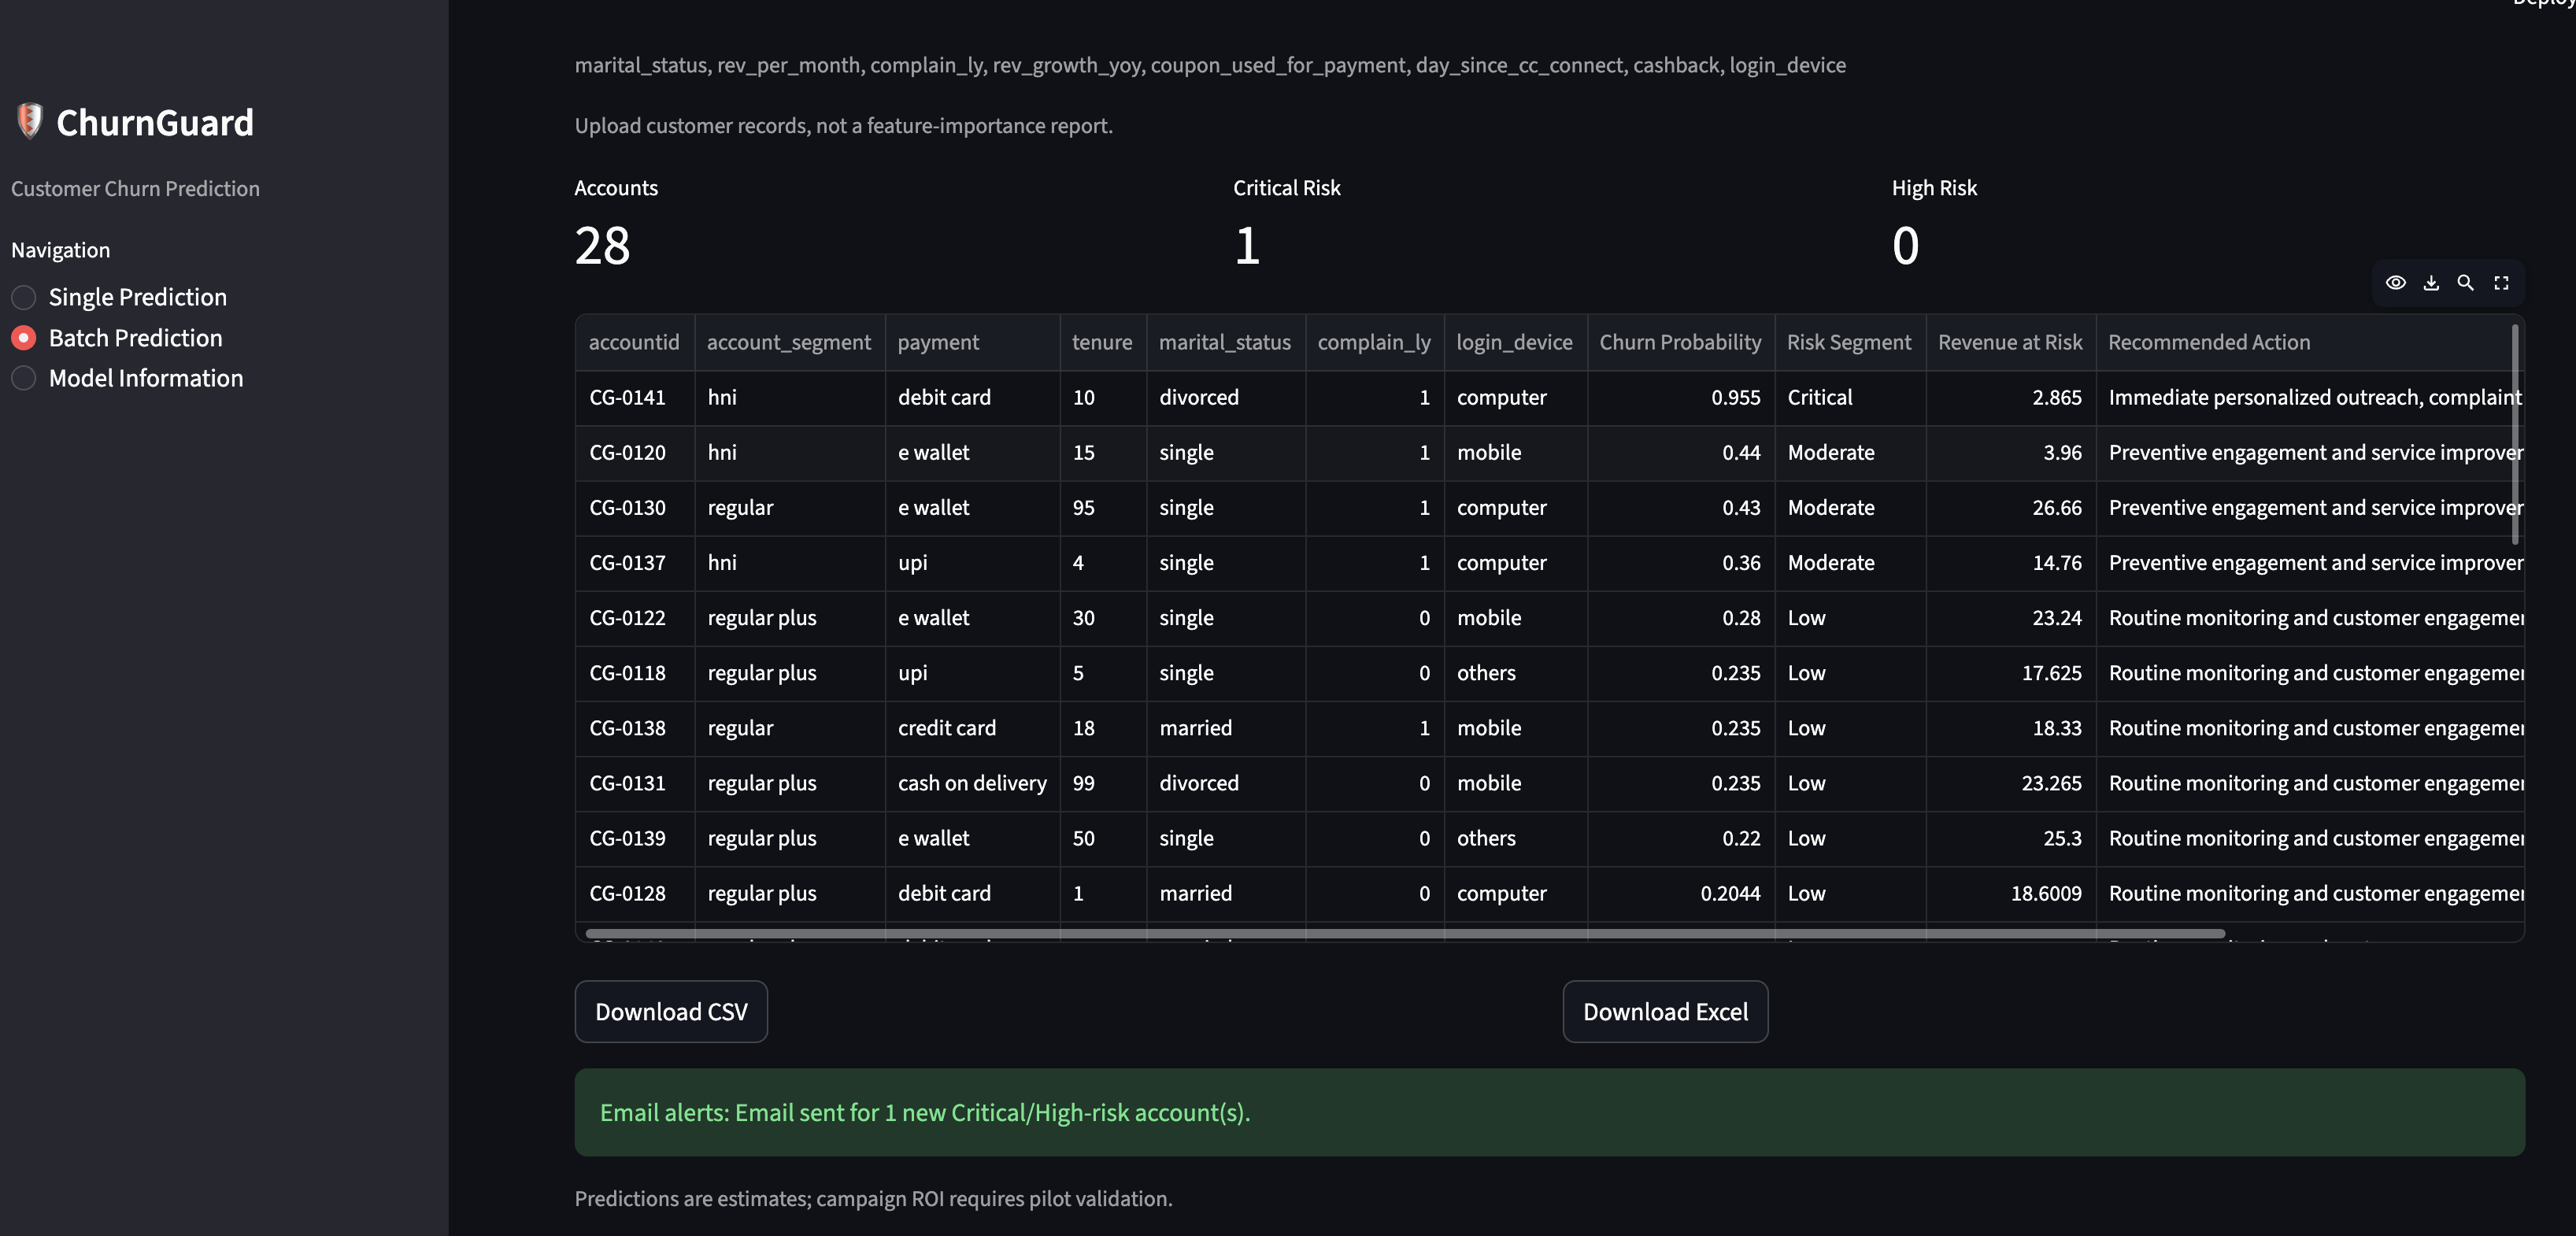


<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 4.5 Automated Prediction and Risk Segmentation

ChurnGuard validates customer datasets and generates churn probabilities using the deployed model. Customers are classified into four risk segments, with revenue at risk calculated as:

$$
\text{Revenue at Risk} = \text{Monthly Revenue} \times \text{Churn Probability}
$$

| Risk     | Probability | Action                    |
| -------- | ----------- | ------------------------- |
| Low      | 0–30%       | Routine monitoring        |
| Moderate | >30–60%     | Preventive engagement     |
| High     | >60–80%     | Targeted retention offers |
| Critical | >80–100%    | Immediate intervention    |

**Sample Prediction Output (Illustrative)**

| Account | Probability | Risk | Revenue at Risk | Recommended Action |
|---|---:|---|---:|---|
| ACC001 | 92% | Critical | 110.40 | Immediate personalized outreach, complaint resolution and tailored incentives |
| ACC002 | 74% | High | 88.80 | Proactive engagement, targeted retention offers and loyalty incentives |
| ACC003 | 12% | Low | 14.40 | Routine monitoring and customer engagement |


<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 4.6 GitHub Actions workflow

**Configure GitHub Actions secrets**
Navigate to GitHub Repository → Settings → Secrets and variables → Actions → New repository secret.
Secret	Value
SMTP_HOST	smtp.gmail.com
SMTP_PORT	587
SMTP_USERNAME	Gmail address
SMTP_PASSWORD	Gmail App Password
SMTP_SENDER	Sender email address
SMTP_RECIPIENTS	Recipient email addresses, comma-separated

In [53]:
%%writefile scripts/predict_changed.py
"""Score changed ChurnGuard datasets and save predictions alongside inputs."""
import argparse
import io
import json
import os
from pathlib import Path
import re
import subprocess
import sys

import joblib
import pandas as pd

INPUT_DIR = Path('data_to_predict')
BOUNDS = {'tenure': (0, 99), 'city_tier': (1, 3), 'cc_contacted_ly': (4, 132), 'service_score': (0, 5), 'account_user_count': (1, 6), 'cc_agent_score': (1, 5), 'rev_per_month': (1, 140), 'complain_ly': (0, 1), 'rev_growth_yoy': (4, 28), 'coupon_used_for_payment': (0, 16), 'day_since_cc_connect': (0, 47), 'cashback': (0, 1997)}
CATEGORIES = {'payment': ['cash on delivery', 'credit card', 'debit card', 'e wallet', 'upi'], 'gender': ['female', 'male'], 'account_segment': ['hni', 'regular', 'regular plus', 'super', 'super plus'], 'marital_status': ['divorced', 'married', 'single'], 'login_device': ['computer', 'mobile', 'others']}
ACTIONS = {'Critical': 'Immediate personalized outreach, complaint resolution and tailored incentives', 'High': 'Proactive engagement, targeted retention offers and loyalty incentives', 'Moderate': 'Preventive engagement and service improvement', 'Low': 'Routine monitoring and customer engagement'}


def is_input(path):
    path = Path(path)
    return (path.parts and path.parts[0] == INPUT_DIR.name
            and path.suffix.lower() in ('.csv', '.xlsx')
            and not path.stem.lower().endswith('_predictions')
            and path.is_file())


def changed_files(before, after):
    if not before or set(before) == {'0'}:
        command = ['git', 'ls-tree', '-r', '--name-only', after, '--', f'{INPUT_DIR}/']
        output = subprocess.check_output(command, text=True)
        paths = output.splitlines()
    else:
        command = ['git', 'diff', '--name-only', '--diff-filter=AMR', before, after, '--', f'{INPUT_DIR}/']
        output = subprocess.check_output(command, text=True)
        paths = output.splitlines()
    return sorted({path for path in paths if is_input(path)})


def read_table(path):
    raw = path.read_bytes()
    if not raw:
        raise ValueError('Empty file')
    if raw.startswith(b'PK\x03\x04'):
        return pd.read_excel(io.BytesIO(raw), engine='openpyxl', dtype={'accountid': 'string'})
    if raw.startswith(b'\xd0\xcf\x11\xe0'):
        raise ValueError('Legacy .xls not supported')
    for encoding in ('utf-8-sig', 'utf-16', 'cp1252', 'latin-1'):
        try:
            df = pd.read_csv(io.StringIO(raw.decode(encoding)), sep=None, engine='python', dtype={'accountid': 'string'})
            if len(df.columns) > 1:
                return df
        except (UnicodeError, pd.errors.ParserError, ValueError):
            pass
    raise ValueError('Unable to parse CSV/XLSX')


def score(df, model, schema):
    df = df.copy()
    df.columns = [re.sub(r'[\s-]+', '_', str(c).strip().lower()) for c in df.columns]
    if df.columns.duplicated().any() or df.empty:
        raise ValueError('Duplicate columns or no rows')
    if 'accountid' not in df:
        raise ValueError('Missing accountid')
    ids = df['accountid'].astype('string').str.strip()
    if ids.isna().any() or ids.eq('').any() or ids.duplicated().any():
        raise ValueError('Blank or duplicate accountid')
    features = schema['features']
    missing = [f for f in features if f not in df.columns]
    if missing:
        raise ValueError('Missing features: ' + ', '.join(missing))
    x = df[features].copy()
    for feature in schema['numeric']:
        x[feature] = pd.to_numeric(x[feature], errors='coerce')
        if feature in BOUNDS:
            lo, hi = BOUNDS[feature]
            if (~x[feature].dropna().between(lo, hi)).any():
                raise ValueError(f'{feature} must be between {lo} and {hi}')
    for feature in schema['categories']:
        x[feature] = x[feature].astype('string').str.strip().str.lower().astype(object)
        if feature in CATEGORIES:
            nonnull = x[feature].dropna()
            invalid = nonnull[~nonnull.isin(CATEGORIES[feature])].unique().tolist()
            if invalid:
                raise ValueError(f'Unsupported {feature}: {invalid}')
    probability = model.predict_proba(x)[:, 1]
    risk = pd.cut(probability, [-.001, .30, .60, .80, 1], labels=['Low', 'Moderate', 'High', 'Critical']).astype(str)
    result = pd.DataFrame({'accountid': ids.to_numpy(), 'Churn Probability': probability, 'Risk Segment': risk})
    result['Revenue at Risk'] = pd.to_numeric(  x['rev_per_month'], errors='coerce' ).to_numpy(dtype=float) * probability
    result['Recommended Action'] = [ACTIONS[r] for r in risk]
    return result.sort_values('Churn Probability', ascending=False).reset_index(drop=True)


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument('--before', default=os.getenv('BEFORE_SHA', ''))
    parser.add_argument('--after', default=os.getenv('GITHUB_SHA', 'HEAD'))
    parser.add_argument('--all', action='store_true', help='Score all input CSV/XLSX files in data_to_predict/')
    args = parser.parse_args()

    files = (sorted(str(path) for path in INPUT_DIR.rglob('*') if is_input(path))
             if args.all else changed_files(args.before, args.after))
    if not files:
        print('No added/modified input CSV/XLSX files; nothing to score.')
        return

    schema = json.loads(Path('models/feature_schema.json').read_text(encoding='utf-8'))
    model = joblib.load(Path('models') / schema['model_file'])
    processed, failures = [], []
    for name in files:
        path = Path(name)
        try:
            result = score(read_table(path), model, schema)
            destination = path.with_name(f'{path.stem}_predictions.csv')
            result.to_csv(destination, index=False)
            processed.append({'source': name, 'output': str(destination), 'rows': len(result),
                              'critical': int(result['Risk Segment'].eq('Critical').sum()),
                              'high': int(result['Risk Segment'].eq('High').sum())})
            print(f'Scored {name}: {len(result)} accounts -> {destination}')
        except Exception as exc:
            failures.append({'source': name, 'error': str(exc)})
            print(f'FAILED {name}: {exc}', file=sys.stderr)

    summary = INPUT_DIR / 'run_summary.json'
    summary.write_text(json.dumps({'processed': processed, 'failed': failures}, indent=2), encoding='utf-8')
    if failures:
        raise SystemExit(f'{len(failures)} file(s) failed validation/scoring')
    print(f'Completed successfully: {len(processed)} dataset(s) scored.')


if __name__ == '__main__':
    main()


Overwriting scripts/predict_changed.py


In [56]:
%%writefile scripts/notify_risks.py
"""Send email alerts for newly predicted High and Critical-risk accounts."""
import json,os,hashlib,smtplib,ssl
from pathlib import Path
from email.message import EmailMessage
import pandas as pd

ROOT=Path("data_to_predict")
SUMMARY=ROOT/"run_summary.json"
HISTORY=ROOT/"notification_history.json"

# Load SMTP configuration from environment variables.
required=["SMTP_HOST","SMTP_USERNAME","SMTP_PASSWORD","SMTP_RECIPIENTS"]
missing=[key for key in required if not os.getenv(key)]
print("SMTP environment variables loaded:",", ".join(key for key in required if os.getenv(key)))

# Read only datasets processed by the current workflow run.
summary=json.loads(SUMMARY.read_text(encoding="utf-8"))
files=[Path(item["output"]) for item in summary.get("processed",[])]
history=json.loads(HISTORY.read_text(encoding="utf-8")) if HISTORY.exists() else {}
pending=[]

for path in files:
    df=pd.read_csv(path,dtype={"accountid":"string"})
    alerts=df[df["Risk Segment"].isin(["High","Critical"])]
    for _,row in alerts.iterrows():
        account=str(row["accountid"]).strip()
        risk=str(row["Risk Segment"])
        key=hashlib.sha256(f"{account}|{risk}".encode()).hexdigest()
        if key not in history:
            pending.append((key,row))

if not pending:
    print("No new High/Critical-risk accounts to notify.")
else:
    if missing:
        raise ValueError("Missing SMTP secrets: "+", ".join(missing))

    # Prepare email notification.
    lines=["ChurnGuard early warning — new high-risk accounts","",
           "Account ID | Risk | Churn Probability | Recommended Action"]
    for _,row in pending:
        lines.append(
            f"{row['accountid']} | {row['Risk Segment']} | "
            f"{row['Churn Probability']:.1%} | {row['Recommended Action']}"
        )

    msg=EmailMessage()
    msg["Subject"]=f"ChurnGuard: {len(pending)} new high-risk account(s)"
    msg["From"]=os.getenv("SMTP_SENDER") or os.environ["SMTP_USERNAME"]
    msg["To"]=os.environ["SMTP_RECIPIENTS"]
    msg.set_content("\n".join(lines))

    # Send email using Gmail SMTP.
    host=os.environ["SMTP_HOST"]
    port=int(os.getenv("SMTP_PORT","587"))
    user=os.environ["SMTP_USERNAME"]
    password=os.environ["SMTP_PASSWORD"]

    if port==465:
        with smtplib.SMTP_SSL(host,port,context=ssl.create_default_context(),timeout=30) as smtp:
            smtp.login(user,password)
            smtp.send_message(msg)
    else:
        with smtplib.SMTP(host,port,timeout=30) as smtp:
            smtp.starttls(context=ssl.create_default_context())
            smtp.login(user,password)
            smtp.send_message(msg)

    # Record successful notifications to prevent duplicate alerts.
    for key,row in pending:
        history[key]={"accountid":str(row["accountid"]),"risk":str(row["Risk Segment"])}

    HISTORY.write_text(json.dumps(history,indent=2),encoding="utf-8")
    print(f"Email sent for {len(pending)} new High/Critical-risk account(s).")


Writing scripts/notify_risks.py


In [ ]:
%%writefile .github/workflows/churnguard-predict.yml
name: ChurnGuard - Automated Churn Prediction

on:
  push:
    branches: [main]
    paths:
      - 'data_to_predict/**/*.csv'
      - 'data_to_predict/**/*.xlsx'
      - '!data_to_predict/**/*_predictions.csv'
  workflow_dispatch:

permissions:
  contents: write

concurrency:
  group: churnguard-prediction
  cancel-in-progress: false

jobs:
  score:
    name: Automated Churn Prediction
    runs-on: ubuntu-latest
    timeout-minutes: 20

    steps:
      - name: Checkout repository
        uses: actions/checkout@v7
        with:
          fetch-depth: 0
          persist-credentials: true

      - name: Set up Python
        uses: actions/setup-python@v7
        with:
          python-version: '3.11'
          cache: pip
          cache-dependency-path: requirements.txt

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          python -m pip install -r requirements.txt

      - name: Verify ChurnGuard files
        run: |
          test -f models/feature_schema.json
          test -f scripts/predict_changed.py
          test -f scripts/preprocessing.py
          python - <<'PY'
          import json
          from pathlib import Path

          schema=json.loads(Path('models/feature_schema.json').read_text(encoding='utf-8'))
          model_path=Path('models')/schema['model_file']
          assert model_path.is_file(),f'Model not found: {model_path}'
          print(f'Model verified: {model_path}')
          PY

      - name: Verify model loading
        env:
          PYTHONPATH: ${{ github.workspace }}
        run: |
          python - <<'PY'
          import json,joblib
          from pathlib import Path

          schema=json.loads(Path('models/feature_schema.json').read_text(encoding='utf-8'))
          model=joblib.load(Path('models')/schema['model_file'])
          print(f'Model loaded: {type(model.named_steps["classifier"]).__name__}')
          PY

      - name: Run automated churn predictions
        env:
          PYTHONPATH: ${{ github.workspace }}
          BEFORE_SHA: ${{ github.event.before }}
          GITHUB_EVENT_NAME: ${{ github.event_name }}
        run: |
          if [ "$GITHUB_EVENT_NAME" = "workflow_dispatch" ]; then
            python -m scripts.predict_changed --all
          else
            python -m scripts.predict_changed
          fi


      - name: Send high-risk email notifications
        env:
          SMTP_HOST: ${{ secrets.SMTP_HOST }}
          SMTP_PORT: ${{ secrets.SMTP_PORT }}
          SMTP_USERNAME: ${{ secrets.SMTP_USERNAME }}
          SMTP_PASSWORD: ${{ secrets.SMTP_PASSWORD }}
          SMTP_SENDER: ${{ secrets.SMTP_SENDER }}
          SMTP_RECIPIENTS: ${{ secrets.SMTP_RECIPIENTS }}
        run: python -m scripts.notify_risks


      - name: Commit generated predictions
        if: success()
        run: |
          git config user.name "github-actions[bot]"
          git config user.email "41898282+github-actions[bot]@users.noreply.github.com"
          find data_to_predict -type f -name '*_predictions.csv' -print0 | xargs -0 -r git add --
          if [ -f data_to_predict/run_summary.json ]; then
            git add -- data_to_predict/run_summary.json
          fi
          if git diff --cached --quiet; then
            echo "No prediction changes to commit."
          else
            git commit -m "ChurnGuard: Update prediction results"
            git pull --rebase origin main
            git push origin HEAD:main
          fi

      - name: Upload prediction artifacts
        if: always()
        uses: actions/upload-artifact@v7
        with:
          name: churnguard-predictions-${{ github.run_id }}
          path: |
            data_to_predict/**/*_predictions.csv
            data_to_predict/run_summary.json
          if-no-files-found: ignore
          retention-days: 30


Overwriting .github/workflows/churnguard-predict.yml


<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 4.7 Push Deployment Files

```mk
# Add, commit, and push changes to GitHub
    # Initialize Git and push the complete ChurnGuard project
    !git init
    !git branch -M main
    !git status
    !git add .
    !git commit -m "Initial commit: ChurnGuard ML project and Streamlit deployment"
    !git remote add origin https://github.com/****/ChurnGuard.git
    !git push -u origin main

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 4.8 Deployment Validation and Testing

GitHub Actions successfully executed the prediction workflow, generated customer-level results, and committed the output files to GitHub.

| Validation                                  | Status               |
| ------------------------------------------- | -------------------- |
| Model loading and preprocessing             | Passed               |
| Automated dataset scoring                   | Passed               |
| Risk classification and revenue calculation | Passed               |
| Prediction export and GitHub commit         | Passed               |
| Streamlit interface and email alerts        | Pending confirmation |

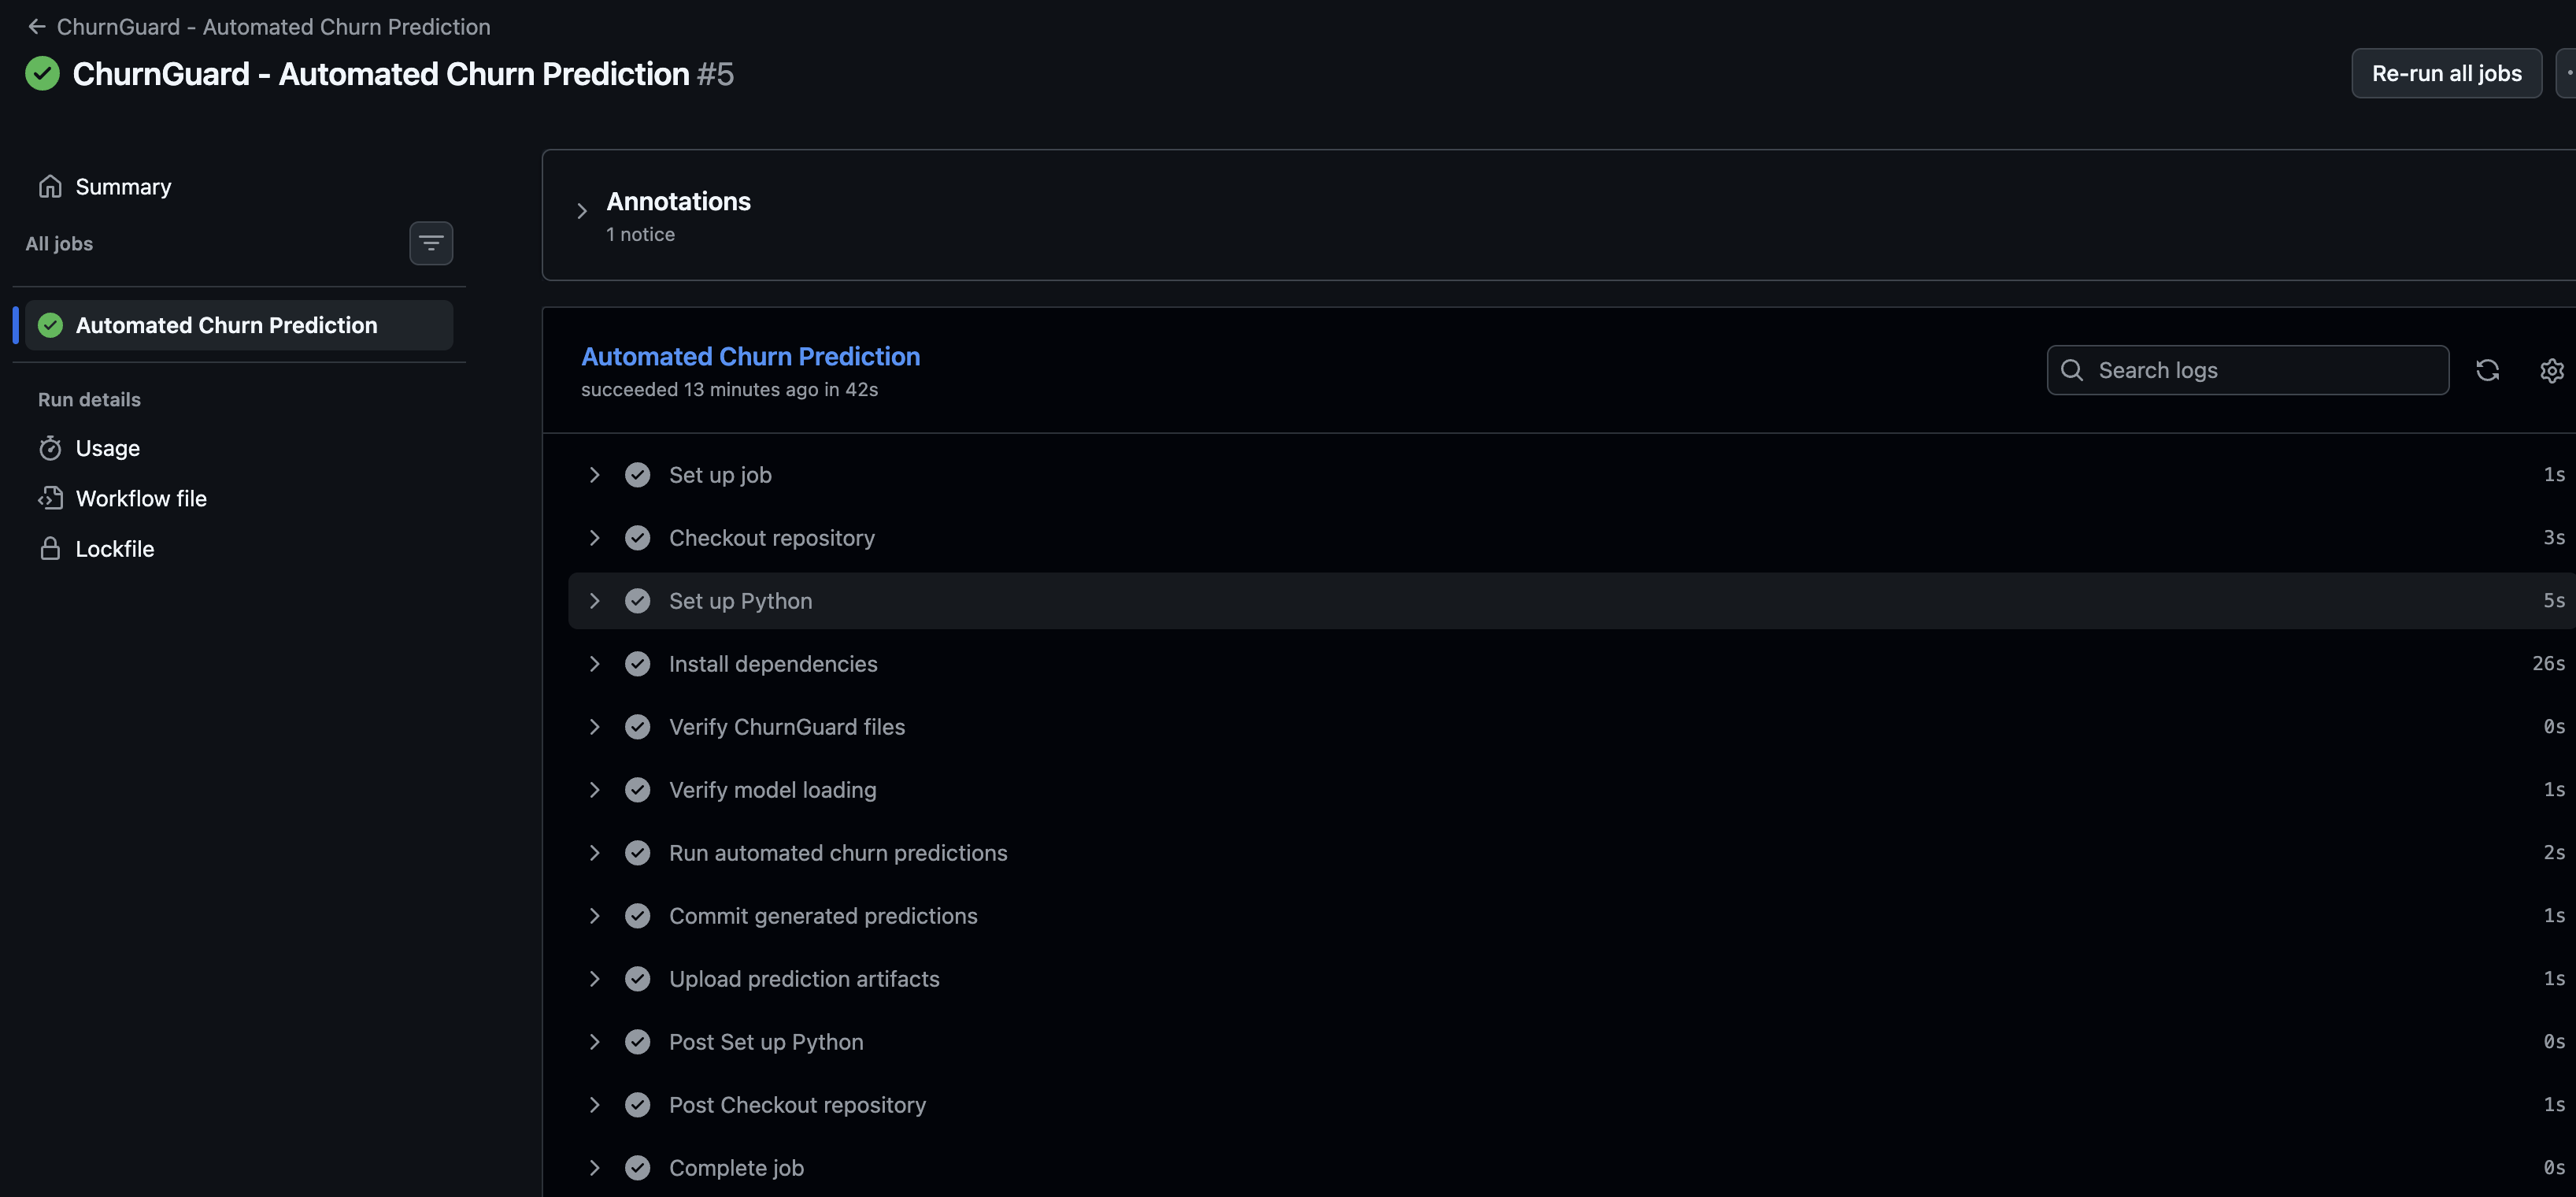


<hr style="border: 0; border-top: 0.5px solid #2b5390;">

### 4.9 Conclusion

ChurnGuard successfully deploys the tuned Extra Trees model for automated churn prediction, risk segmentation, and retention recommendations. GitHub Actions enables repeatable scoring, while Streamlit supports interactive predictions. Future improvements include automated retraining, performance monitoring, and CRM integration.

---
## 3. Business interpretation and ChurnGuard deployment continuity

The model comparison is an **experiment**, not an instruction to overwrite production artifacts. ChurnGuard already performs automated batch predictions on new CSV/XLSX files using `predict_changed.py` and GitHub Actions. Its existing `churnguard_xgboost.joblib` and `feature_schema.json` are the deployment contract, and batch input also requires `accountid` for output identification.

The risk bands **0.30 / 0.60 / 0.80** are existing operational cutoffs, not validated optima. Keep them labeled as business-defined until validated on training/validation data. Compare the selected model with the current production XGBoost model and migrate only after schema and output compatibility checks.


In [26]:
# Deployment compatibility review — no automatic overwrite of existing artifacts.
from pathlib import Path
schema_path = Path("feature_schema.json")
if schema_path.exists():
    with schema_path.open(encoding="utf-8") as f:
        deployed_schema = json.load(f)
    print("Existing feature_schema.json found. Review its expected feature list against:")
    print(list(X_train.columns))
    print("Schema content:", deployed_schema)
else:
    print("No feature_schema.json in this working directory; check repository root.")
print("Final model:", best_model_name)
print("Current ChurnGuard artifact: churnguard_xgboost.joblib")
print("Deployment ready without script migration:", best_model_name == "XGBoost")


No feature_schema.json in this working directory; check repository root.
Final model: Extra Trees
Current ChurnGuard artifact: churnguard_xgboost.joblib
Deployment ready without script migration: False


### 3.1 Export candidate (do not overwrite production automatically)

Save a candidate pipeline for inspection. Before replacing `churnguard_xgboost.joblib`, verify the pipeline input columns, `predict_proba` output, customer identifier handling and `predict_changed.py` integration on a sample file. If a non-XGBoost model wins, update the automation to use a model-agnostic artifact name and test it before deployment.


In [27]:
# Candidate model includes fitted preprocessing. Existing production artifact is untouched.
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
candidate_path = output_dir / "churnguard_candidate_pipeline.joblib"
joblib.dump(best_model, candidate_path)
feature_schema_candidate = {
    "feature_columns": list(X_train.columns),
    "identifier_column": "accountid",
    "target_column": "churn",
    "selected_model": best_model_name,
    "model_artifact": str(candidate_path),
    "risk_thresholds": [0.30, 0.60, 0.80],
    "risk_threshold_status": "business_defined_not_optimized",
}
with (output_dir / "feature_schema_candidate.json").open("w", encoding="utf-8") as f:
    json.dump(feature_schema_candidate, f, indent=2)
print("Candidate exported:", candidate_path)
print("Production files not overwritten.")


Candidate exported: outputs/churnguard_candidate_pipeline.joblib
Production files not overwritten.


### 3.2 Batch-scoring smoke test

This verifies the candidate's prediction interface and input schema. It does **not** prove GitHub Actions compatibility; run `predict_changed.py` against a representative input in a test branch before replacing production artifacts.


In [28]:
sample = X_test.head(5).copy()
assert list(sample.columns) == list(X_train.columns)
probs = best_model.predict_proba(sample)[:, 1]
assert len(probs) == len(sample) and np.isfinite(probs).all()
preview = pd.DataFrame({"accountid": test_accounts.loc[sample.index].values,
                        "churn_probability": probs,
                        "predicted_churn": (probs >= 0.5).astype(int)})
display(preview)


,accountid,churn_probability,predicted_churn
0,29973,0.030556,0
1,29509,0.026048,0
2,24994,0.011626,0
3,30053,0.000000,0
4,20478,0.049693,0
